# 04 — Late Delivery Root Cause & Revenue Exposure
**Question:** 55% of order lines arrive late. Why, and what is it worth fixing?

A late flag means *actual shipping days > promised (scheduled) days*. So lateness has two possible causes:
1. **Execution:** the shipment is slower than it should be.
2. **Promise:** the promise was unrealistic to begin with.

This notebook separates the two.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import chart_style as cs
cs.apply()

df = pd.read_csv('../data/processed/order_lines_clean.csv', parse_dates=['order_date'])
s = df[df.is_cancelled == 0].copy()          # cancelled / fraud orders never ship
MODES = ['Same Day', 'First Class', 'Second Class', 'Standard Class']
print(f'{len(s):,} shipped order lines | overall late rate {s.late_delivery_risk.mean():.1%}')

172,765 shipped order lines | overall late rate 57.3%


## 1. Promised vs actual days by shipping mode

In [2]:
perf = s.groupby('shipping_mode').agg(order_lines=('order_item_id', 'size'), revenue=('sales', 'sum'),
                                       promised=('ship_days_promised', 'mean'), actual_avg=('ship_days_actual', 'mean'),
                                       actual_min=('ship_days_actual', 'min'), actual_max=('ship_days_actual', 'max'),
                                       late_rate=('late_delivery_risk', 'mean')).reindex(MODES)
perf['rev_share'] = perf.revenue / perf.revenue.sum()
perf.round(3)

,order_lines,revenue,promised,actual_avg,actual_min,actual_max,late_rate,rev_share
shipping_mode,,,,,,,,
Same Day,9293,1854872.17,0.0,0.479,0,1,0.479,0.053
First Class,26513,5408068.46,1.0,2.000,2,2,1.000,0.154
Second Class,33806,6860661.43,2.0,3.993,2,6,0.798,0.195
Standard Class,103153,21090826.92,4.0,3.994,2,6,0.398,0.599


In [3]:
dist = pd.crosstab(s.shipping_mode, s.ship_days_actual, normalize='index').reindex(MODES)
dist.round(3)

ship_days_actual,0,1,2,3,4,5,6
shipping_mode,,,,,,,
Same Day,0.521,0.479,0.000,0.000,0.000,0.000,0.000
First Class,0.000,0.000,1.000,0.000,0.000,0.000,0.000
Second Class,0.000,0.000,0.202,0.200,0.200,0.200,0.198
Standard Class,0.000,0.000,0.202,0.201,0.199,0.196,0.202


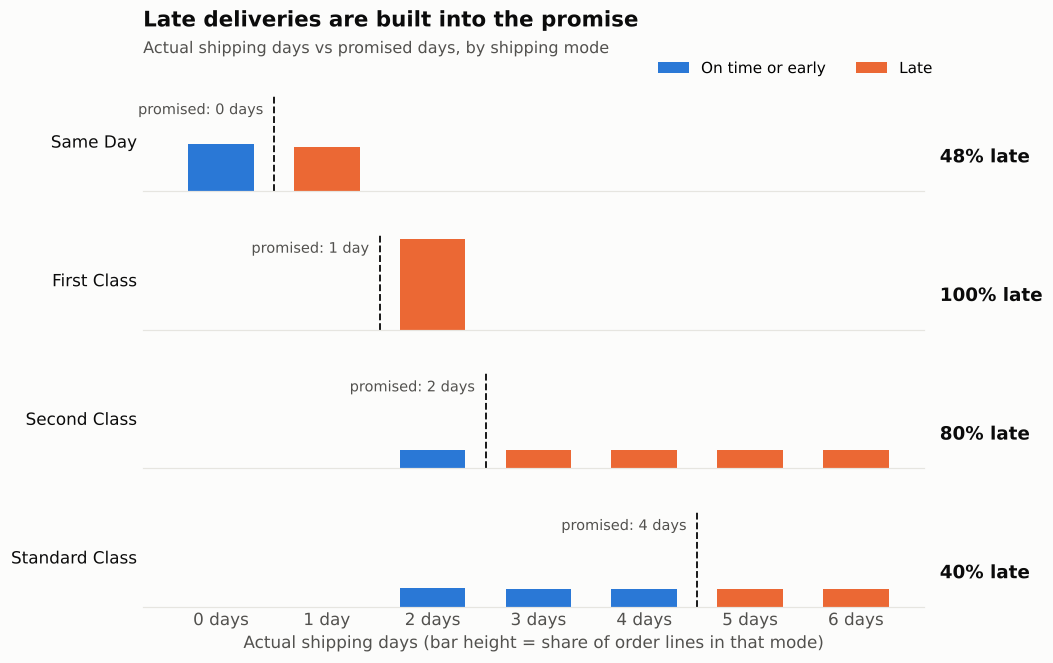

In [4]:
from matplotlib.transforms import blended_transform_factory as blend
fig, axes = plt.subplots(len(MODES), 1, figsize=(10, 6.2), sharex=True)
days = np.arange(0, 7)
for ax, mode in zip(axes, MODES):
    share = dist.loc[mode].reindex(days, fill_value=0)
    promise = perf.loc[mode, 'promised']
    ax.bar(days, share.values, color=[cs.ORANGE if d > promise else cs.BLUE for d in days], width=0.62)
    ax.axvline(promise + 0.5, color=cs.INK, lw=1.2, ls='--')
    ax.text(promise + 0.4, 0.92, f'promised: {promise:.0f} day{"s" if promise != 1 else ""}',
            transform=blend(ax.transData, ax.transAxes), va='top', ha='right', fontsize=9.5, color=cs.INK_2)
    ax.set_ylabel(mode, rotation=0, ha='right', va='center', fontsize=11, color=cs.INK)
    ax.text(1.02, 0.35, f'{perf.loc[mode, "late_rate"]:.0%} late', transform=ax.transAxes, va='center',
            fontsize=12, fontweight='bold', color=cs.INK)
    ax.set_ylim(0, 1.05); ax.set_yticks([]); ax.grid(False); ax.spines['left'].set_visible(False)
axes[-1].set_xticks(days, [f'{d} day{"s" if d != 1 else ""}' for d in days])
axes[-1].set_xlabel('Actual shipping days (bar height = share of order lines in that mode)')
axes[0].bar(0, 0, color=cs.BLUE, label='On time or early'); axes[0].bar(0, 0, color=cs.ORANGE, label='Late')
fig.legend(loc='upper right', ncol=2, bbox_to_anchor=(0.9, 0.93))
fig.text(0.17, 0.985, 'Late deliveries are built into the promise', fontsize=14, fontweight='bold', color=cs.INK, va='top')
fig.text(0.17, 0.94, 'Actual shipping days vs promised days, by shipping mode', fontsize=10.5, color=cs.INK_2, va='top')
plt.subplots_adjust(hspace=0.45, left=0.17, right=0.88, top=0.86)
plt.savefig('../images/05_promise_vs_actual_by_mode.png'); plt.show()

**Findings**
- **First Class** promises 1 day but takes **exactly 2 days, every time**: 100% of shipped lines are late. That's a broken promise, not a failure to execute.
- **Second Class** promises 2 days, but actual transit is **spread evenly from 2 to 6 days**, the *same* distribution as Standard Class. Customers pay for a faster service and get Standard transit.
- **Standard Class** promises 4 days against the same 2–6 day spread, so about 40% of its lines arrive late.
- **Same Day** ships in 0–1 days against a 0-day promise, so about half are late.

### Is Second Class really the same as Standard Class?

In [5]:
from scipy.stats import chi2_contingency
tab = pd.crosstab(s.loc[s.shipping_mode.isin(['Second Class', 'Standard Class']), 'shipping_mode'],
                  s.loc[s.shipping_mode.isin(['Second Class', 'Standard Class']), 'ship_days_actual'])
chi2, pval, dof, _ = chi2_contingency(tab)
print(tab, f'\nChi-square p-value = {pval:.3f}')

ship_days_actual      2      3      4      5      6
shipping_mode                                      
Second Class       6819   6759   6759   6772   6697
Standard Class    20873  20719  20538  20231  20792 
Chi-square p-value = 0.401


A high p-value means the two transit-time distributions are statistically **indistinguishable**. Second Class adds no speed.

## 2. Do other factors matter?

In [6]:
checks = {}
for col in ['market', 'order_region', 'customer_segment', 'department_name', 'payment_type']:
    r = s.groupby(['shipping_mode', col]).late_delivery_risk.mean().unstack()
    checks[col] = (r.max(axis=1) - r.min(axis=1)).reindex(MODES)
spread = pd.DataFrame(checks)
print('Spread (max − min) in late rate WITHIN each shipping mode, across each factor:')
spread.round(3)

Spread (max − min) in late rate WITHIN each shipping mode, across each factor:


,market,order_region,customer_segment,department_name,payment_type
shipping_mode,,,,,
Same Day,0.050,0.464,0.042,0.377,0.029
First Class,0.000,0.000,0.000,0.000,0.000
Second Class,0.013,0.168,0.018,0.083,0.019
Standard Class,0.005,0.144,0.014,0.047,0.013


Within any one shipping mode, the late rate barely moves across markets, regions, customer segments, departments or payment types (Same Day and some small regions vary more only because their samples are small).
**Shipping mode, through its promise, explains essentially all of the lateness.**

## 3. Does lateness cost customers?

In [7]:
orders = (s.sort_values('order_date').groupby('order_id')
          .agg(customer_id=('customer_id', 'first'), order_date=('order_date', 'first'),
               late=('late_delivery_risk', 'max'), revenue=('sales', 'sum')))
orders['order_n'] = orders.sort_values('order_date').groupby('customer_id').cumcount() + 1
n_orders = orders.groupby('customer_id').size()
first = orders[orders.order_n == 1].copy()
first['came_back'] = first.customer_id.map(n_orders) > 1
first = first[first.order_date < '2017-06-01']        # leave time to observe a repeat order
first.groupby('late').agg(customers=('came_back', 'size'), repeat_rate=('came_back', 'mean')).rename(index={0: 'first order on time', 1: 'first order late'}).round(3)

,customers,repeat_rate
late,,
first order on time,5247,0.950
first order late,6945,0.956


**Honest result:** customers whose first order arrived late came back at the **same rate** (about 95%) as customers whose first order was on time. This data shows **no measurable churn effect**, so this analysis does **not** claim lost revenue from lateness.

The business risk is still real, just not visible in this dataset:
- **Revenue exposure:** a large share of revenue is delivered late (quantified below).
- **Premium-service integrity:** First and Second Class customers don't get what the service name promises. That's a refund, complaint and trust risk.

## 4. What fixing it is worth — scenarios
Two levers, tested against the actual shipment history:

| Scenario | What changes | New promise (days) |
|---|---|---|
| **A. Promise reset** (no operational change) | Promise what each mode actually delivers | Same Day 1 · First 2 · Second 4 · Standard 5 |
| **B. A + reroute Second Class** | Ship Second Class through the First Class lane, which delivers in exactly 2 days every time | Second Class promise 3 (still slower than First Class's 2) |

In [8]:
PROMISE_A = {'Same Day': 1, 'First Class': 2, 'Second Class': 4, 'Standard Class': 5}
s['promise_a'] = s.shipping_mode.map(PROMISE_A)
s['late_a'] = (s.ship_days_actual > s.promise_a).astype(int)

is_2nd = s.shipping_mode == 'Second Class'
s['days_b'] = s.ship_days_actual.where(~is_2nd, 2)                 # First Class lane: always 2 days
s['promise_b'] = s.promise_a.where(~is_2nd, 3)
s['late_b'] = (s.days_b > s.promise_b).astype(int)

scen = pd.DataFrame({
    'promise_now': perf.promised, 'late_now': perf.late_rate,
    'promise_A': pd.Series(PROMISE_A), 'late_A': s.groupby('shipping_mode').late_a.mean(),
    'promise_B': s.groupby('shipping_mode').promise_b.first(), 'late_B': s.groupby('shipping_mode').late_b.mean()}).reindex(MODES)
scen.loc['ALL MODES', ['late_now', 'late_A', 'late_B']] = [s.late_delivery_risk.mean(), s.late_a.mean(), s.late_b.mean()]
scen.round(3)

,promise_now,late_now,promise_A,late_A,promise_B,late_B
Same Day,0.0,0.479,1.0,0.000,1.0,0.000
First Class,1.0,1.000,2.0,0.000,2.0,0.000
Second Class,2.0,0.798,4.0,0.398,3.0,0.000
Standard Class,4.0,0.398,5.0,0.202,5.0,0.202
ALL MODES,NaN,0.573,NaN,0.198,NaN,0.120


In [9]:
years = (s.order_date.max() - s.order_date.min()).days / 365.25
premium_rev = s.loc[s.shipping_mode.isin(['First Class', 'Second Class']), 'sales'].sum()
exposure = pd.DataFrame({
    'late_rate': [s.late_delivery_risk.mean(), s.late_a.mean(), s.late_b.mean()],
    'revenue_delivered_late': [s.loc[s[c] == 1, 'sales'].sum() for c in ['late_delivery_risk', 'late_a', 'late_b']],
}, index=['Today', 'A: promise reset', 'B: reset + reroute Second Class'])
exposure['per_year'] = exposure.revenue_delivered_late / years
print(f'Premium-mode (First + Second Class) revenue sold on a promise it cannot meet: ${premium_rev/1e6:.1f}M (${premium_rev/years/1e6:.1f}M per year)')
exposure.round(3)

Premium-mode (First + Second Class) revenue sold on a promise it cannot meet: $12.3M ($4.0M per year)


,late_rate,revenue_delivered_late,per_year
Today,0.573,20126394.88,6528566.368
A: promise reset,0.198,6972917.23,2261863.249
B: reset + reroute Second Class,0.120,4225378.30,1370621.158


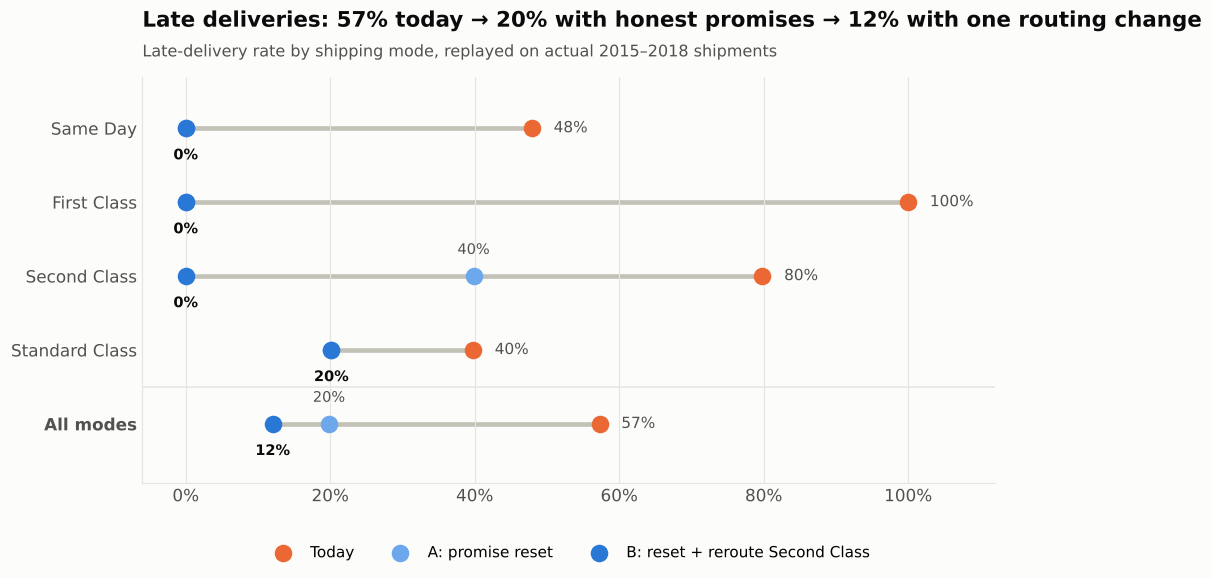

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.8))
labels = MODES + ['All modes']
now, a, b = scen['late_now'].values, scen['late_A'].values, scen['late_B'].values
y = np.arange(len(labels))[::-1]
for yy, n_, b_ in zip(y, now, b):
    ax.plot([min(b_, n_), n_], [yy, yy], color=cs.GREY, lw=3, solid_capstyle='round', zorder=1)
ax.scatter(now, y, s=110, color=cs.ORANGE, zorder=2, label='Today')
ax.scatter(a, y, s=110, color=cs.BLUE_RAMP[2], zorder=3, label='A: promise reset')
ax.scatter(b, y, s=110, color=cs.BLUE, zorder=4, label='B: reset + reroute Second Class')
for yy, n_, a_, b_ in zip(y, now, a, b):
    ax.text(n_ + 0.03, yy, f'{n_:.0%}', va='center', color=cs.INK_2, fontsize=10)
    if abs(a_ - b_) > 0.005:
        ax.text(a_, yy + 0.3, f'{a_:.0%}', ha='center', color=cs.INK_2, fontsize=9.5)
    ax.text(b_, yy - 0.42, f'{b_:.0%}', ha='center', color=cs.INK, fontsize=9.5, fontweight='bold')
ax.set_yticks(y, labels); ax.get_yticklabels()[-1].set_fontweight('bold')
ax.xaxis.set_major_formatter(cs.pct_fmt); ax.set_xlim(-0.06, 1.12); ax.set_ylim(-0.8, len(labels) - 0.3)
ax.grid(axis='y', visible=False); ax.axhline(0.5, color=cs.GRID, lw=1)
ax.legend(loc='upper center', ncol=3, bbox_to_anchor=(0.5, -0.12))
cs.titles(ax, f'Late deliveries: {now[-1]:.0%} today → {a[-1]:.0%} with honest promises → {b[-1]:.0%} with one routing change',
          'Late-delivery rate by shipping mode, replayed on actual 2015–2018 shipments')
plt.savefig('../images/06_late_rate_scenario.png'); plt.show()

## Summary
- Lateness is **systemic, not random**: it comes from promise settings and from carrier transit times that vary from 2 to 6 days. It does not come from any particular market, product or customer group.
- **First Class** is 100% late by design, and **Second Class** is a Standard-speed service sold as premium.
- **Scenario A** (promise what is actually delivered) cuts late deliveries by roughly two-thirds **with no operational change**.
- **Scenario B** (route Second Class through the 2-day First Class lane) cuts them further and makes the premium tier real. The only lateness left is in Standard Class's 2–6 day carrier spread, the next carrier-negotiation target.

In [11]:
import os; os.makedirs('../results', exist_ok=True)
scen.round(4).to_csv('../results/delivery_scenarios.csv')
exposure.round(2).to_csv('../results/delivery_revenue_exposure.csv')
print('Saved results/delivery_scenarios.csv and results/delivery_revenue_exposure.csv')

Saved results/delivery_scenarios.csv and results/delivery_revenue_exposure.csv
